<a href="https://colab.research.google.com/github/ariannalog/Differential-Privacy-Thesis-Evaluations/blob/main/Differential_Privacy_Thesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Dataset Setup**

The Adult Census dataset was imported by combining the training and testing data into a single dataset containing 48,842 records. The dataset was downloaded directly from the UCI Machine Learning Repository.

We also examine the distribution of the education variable by counting the number of individuals in each of the 16 education categories. The resulting counts are displayed in descending order and will be used as utility values in the Exponential Mechanism experiments.

In [43]:

import pandas as pd

url_data = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
url_test = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"

columns = ["age", "workclass", "fnlwgt", "education", "education_num",
           "marital_status", "occupation", "relationship", "race", "sex",
           "capital_gain", "capital_loss", "hours_per_week",
           "native_country", "income"]

df_data = pd.read_csv(url_data, header=None, names=columns,
                      skipinitialspace=True, na_values="?")
df_test = pd.read_csv(url_test, header=None, names=columns,
                      skiprows=1, skipinitialspace=True, na_values="?")

df_test["income"] = df_test["income"].str.rstrip(".")
df = pd.concat([df_data, df_test], ignore_index=True)

print("Number of records:", len(df))

education_counts = df["education"].value_counts()

print("\nNumber of individuals in each education category:")
print(education_counts)


Number of records: 48842

Number of individuals in each education category:
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
Name: count, dtype: int64


**Laplace Mechanism - Mean Absolute Error**

To evaluate the accuracy of the Laplace Mechanism, we consider three counting queries with different true counts: Bachelors, Doctorate, and Preschool.

For each query, we apply the mechanism using four different values of $\varepsilon$: 0.1, 0.2, 0.5, and 1.0. Each experiment is repeated 1,000 times to estimate the empirical Mean Absolute Error (MAE).

The empirical MAE is then compared with its theoretical value, which is equal to $1/\varepsilon$ for queries with sensitivity 1.

The generated noise is also stored for subsequent analysis of its distribution.

In [44]:
import numpy as np
import pandas as pd

epsilons = [0.1, 0.2, 0.5, 1.0]

n_runs = 1000

rng = np.random.default_rng(123)

true_counts = {
    "Bachelors": (df["education"] == "Bachelors").sum(),
    "Doctorate": (df["education"] == "Doctorate").sum(),
    "Preschool": (df["education"] == "Preschool").sum()
}

results = []
noise_results = {}

for epsilon in epsilons:

    b = 1 / epsilon

    noise_results[epsilon] = {}

    for query_name, true_count in true_counts.items():

        noise = rng.laplace(
            loc=0,
            scale=b,
            size=n_runs
        )

        noise_results[epsilon][query_name] = noise

        noisy_counts = true_count + noise

        empirical_mae = np.mean(
            np.abs(noisy_counts - true_count)
        )

        results.append({
            "Epsilon": epsilon,
            "Query": query_name,
            "Empirical MAE": empirical_mae,
            "Theoretical MAE": 1 / epsilon
        })

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

 Epsilon     Query  Empirical MAE  Theoretical MAE
     0.1 Bachelors          9.731             10.0
     0.1 Doctorate          9.881             10.0
     0.1 Preschool          9.910             10.0
     0.2 Bachelors          4.784              5.0
     0.2 Doctorate          4.893              5.0
     0.2 Preschool          5.161              5.0
     0.5 Bachelors          1.946              2.0
     0.5 Doctorate          1.892              2.0
     0.5 Preschool          1.981              2.0
     1.0 Bachelors          0.984              1.0
     1.0 Doctorate          1.052              1.0
     1.0 Preschool          0.977              1.0


**Laplace Mechanism - Noise Distribution**

In this section, we analyze how the noise generated by the Laplace Mechanism is distributed around zero and how its distribution changes for different values of $\varepsilon$.

For each value of $\varepsilon$, we use the 1,000 noise samples previously generated during the MAE evaluation. These samples are obtained by subtracting the real count from each noisy count.

We then plot a histogram of the empirical noise distribution and compare it with the theoretical Laplace probability density function (PDF), considering a sensitivity equal to 1.

This comparison allows us to observe how increasing $\varepsilon$ produces a more concentrated noise distribution around zero.

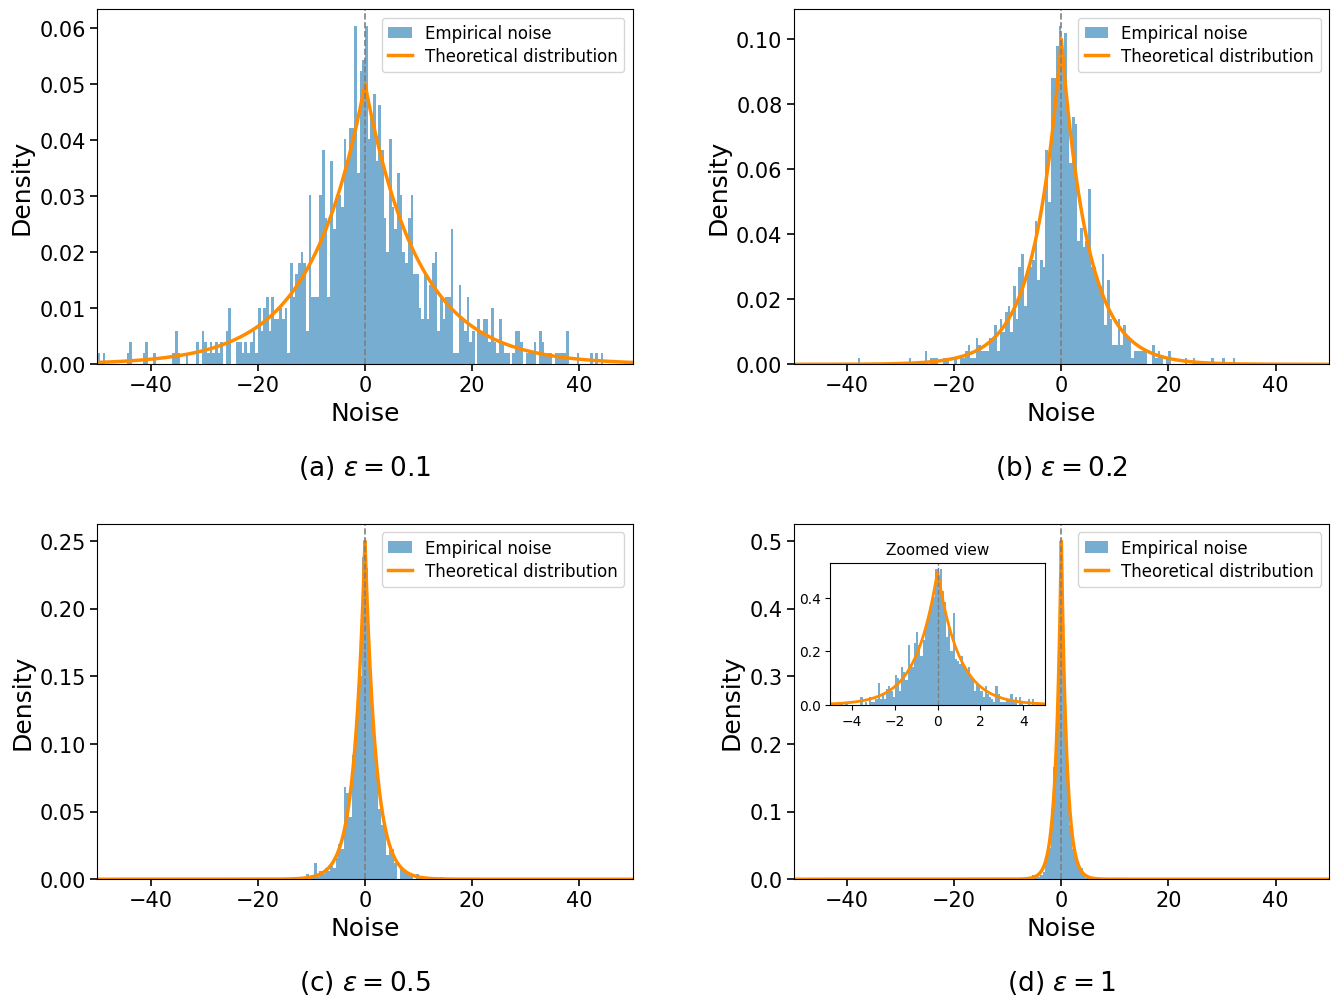

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

x = np.linspace(-50, 50, 2001)


def draw_plot(ax, epsilon, letter):

    ax.hist(
        noise_results[epsilon]["Bachelors"],
        bins=np.linspace(-50, 50, 201),
        density=True,
        alpha=0.6,
        label="Empirical noise"
    )

    pdf = (epsilon / 2) * np.exp(-epsilon * np.abs(x))

    ax.plot(
        x, pdf,
        color="darkorange",
        linewidth=2.5,
        label="Theoretical distribution"
    )

    ax.axvline(0, color="gray", linestyle="--", linewidth=1.2)

    ax.set_xlim(-50, 50)
    ax.set_xlabel("Noise", fontsize=18, labelpad=4)
    ax.set_ylabel("Density", fontsize=18, labelpad=4)

    ax.tick_params(
        axis="both",
        labelsize=15,
        pad=3,
        width=1.2,
        length=5
    )

    ax.legend(
        fontsize=12,
        loc="upper right",
        handlelength=1.4,
        borderpad=0.4,
        labelspacing=0.3
    )

    ax.text(
        0.5, -0.25,
        rf"({letter}) $\varepsilon = {epsilon:g}$",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=19
    )

    if epsilon == 1:

        axins = inset_axes(
            ax,
            width="40%",
            height="40%",
            loc="upper left",
            bbox_to_anchor=(0.03, -0.05, 1, 1),
            bbox_transform=ax.transAxes,
            borderpad=1.5
        )

        axins.hist(
            noise_results[epsilon]["Bachelors"],
            bins=np.linspace(-5, 5, 101),
            density=True,
            alpha=0.6
        )

        x_zoom = np.linspace(-5, 5, 500)
        pdf_zoom = (epsilon / 2) * np.exp(-epsilon * np.abs(x_zoom))

        axins.plot(
            x_zoom,
            pdf_zoom,
            color="darkorange",
            linewidth=2
        )

        axins.axvline(
            0,
            color="gray",
            linestyle="--",
            linewidth=1
        )

        axins.set_xlim(-5, 5)
        axins.set_title("Zoomed view", fontsize=11)
        axins.tick_params(axis="both", labelsize=10)


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

fig.subplots_adjust(
    left=0.09,
    right=0.97,
    bottom=0.10,
    top=0.97,
    hspace=0.45,
    wspace=0.30
)

letters = ["a", "b", "c", "d"]

for ax, epsilon, letter in zip(axes.flat, epsilons[:4], letters):
    draw_plot(ax, epsilon, letter)

fig.savefig("laplace_noise.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

**Laplace Mechanism - Effect of Count Size on Relative Error**

In this experiment, we compare the empirical and theoretical Relative MAE for three counting queries: Bachelors, Doctorate, and Preschool.

For each value of $\varepsilon$, we generate 1,000 independent Laplace noise samples. The same noise samples are used for all three queries, allowing us to compare the relative impact of noise on counts of different sizes.

We calculate the empirical Relative MAE and compare it with its theoretical value. The results are then displayed in a plot, using a logarithmic scale on the y-axis to better visualize the differences between the three queries.



 Epsilon     Query  Empirical Relative MAE  Theoretical Relative MAE
     0.1 Bachelors                0.001213                  0.001246
     0.1 Doctorate                0.016383                  0.016835
     0.1 Preschool                0.117247                  0.120482
     0.2 Bachelors                0.000616                  0.000623
     0.2 Doctorate                0.008318                  0.008418
     0.2 Preschool                0.059525                  0.060241
     0.5 Bachelors                0.000247                  0.000249
     0.5 Doctorate                0.003337                  0.003367
     0.5 Preschool                0.023878                  0.024096
     1.0 Bachelors                0.000119                  0.000125
     1.0 Doctorate                0.001611                  0.001684
     1.0 Preschool                0.011527                  0.012048


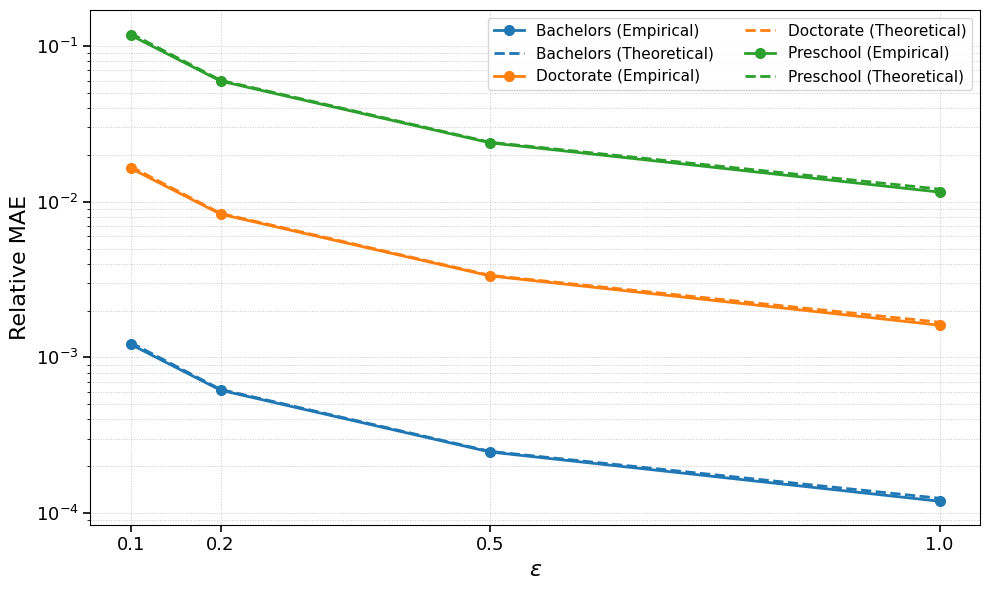

In [46]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

epsilons = [0.1, 0.2, 0.5, 1]
n_runs = 1000
rng = np.random.default_rng(123)

true_counts = {
    "Bachelors": (df["education"] == "Bachelors").sum(),
    "Doctorate": (df["education"] == "Doctorate").sum(),
    "Preschool": (df["education"] == "Preschool").sum()
}

results = []

for epsilon in epsilons:

    b = 1 / epsilon

    noise = rng.laplace(
        loc=0,
        scale=b,
        size=n_runs
    )

    empirical_mae = np.mean(np.abs(noise))

    for query_name, true_count in true_counts.items():

        empirical_relative_mae = empirical_mae / true_count

        theoretical_relative_mae = 1 / (epsilon * true_count)

        results.append({
            "Epsilon": epsilon,
            "Query": query_name,
            "Empirical Relative MAE": empirical_relative_mae,
            "Theoretical Relative MAE": theoretical_relative_mae
        })

results_df = pd.DataFrame(results)

print(results_df.round(6).to_string(index=False))


fig, ax = plt.subplots(figsize=(10, 6))

for query_name in true_counts:

    query_results = results_df[
        results_df["Query"] == query_name
    ].sort_values("Epsilon")

    line, = ax.plot(
        query_results["Epsilon"],
        query_results["Empirical Relative MAE"],
        marker="o",
        linewidth=2,
        markersize=7,
        label=f"{query_name} (Empirical)"
    )

    ax.plot(
        query_results["Epsilon"],
        query_results["Theoretical Relative MAE"],
        linestyle="--",
        linewidth=2,
        color=line.get_color(),
        label=f"{query_name} (Theoretical)"
    )

ax.set_xlabel(r"$\varepsilon$", fontsize=16)
ax.set_ylabel("Relative MAE", fontsize=16)

ax.set_xticks(epsilons)
ax.set_yscale("log")

ax.tick_params(
    axis="both",
    labelsize=13,
    width=1.2,
    length=5
)

ax.grid(
    True,
    which="both",
    linestyle=":",
    linewidth=0.7,
    alpha=0.7
)

ax.legend(
    fontsize=11,
    loc="best",
    ncol=2
)

fig.tight_layout()

fig.savefig(
    "laplace_relative_mae.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)



**Exponential Mechanism: Definition of Categories and Exponential Mechanism**

In this experiment, we consider the 16 possible education categories in the Adult Census dataset.

The utility function is defined as the number of individuals belonging to each education category. Therefore, categories with higher counts have higher utility values.

The optimal category is the one with the highest utility, which is HS-grad in our dataset, with 15,784 individuals.

We then implement the Exponential Mechanism, which assigns a selection probability to each category based on its utility value, the privacy parameter $\varepsilon$, and a utility sensitivity equal to 1.

The mechanism randomly selects a category according to the resulting probability distribution. It will be used in the following experiments to evaluate the selection accuracy for different values of $\varepsilon$.

In [47]:

categories = np.array([
    "Bachelors", "Some-college", "11th", "HS-grad",
    "Prof-school", "Assoc-acdm", "Assoc-voc", "9th",
    "7th-8th", "12th", "Masters", "1st-4th",
    "10th", "Doctorate", "5th-6th", "Preschool"
])

education_counts = df["education"].value_counts()
utilities = education_counts.reindex(
    categories, fill_value=0
).to_numpy()

optimal_category = categories[np.argmax(utilities)]

print("Optimal category:", optimal_category)

rng = np.random.default_rng(123)

def exponential_mechanism(categories, utilities, epsilon):
    sensitivity = 1

    scores = epsilon * utilities / (2 * sensitivity)
    weights = np.exp(scores - np.max(scores))
    probabilities = weights / np.sum(weights)

    return rng.choice(categories, p=probabilities)


Optimal category: HS-grad


**Exponential Mechanism - Selection Success Rate**

In this experiment, we evaluate the performance of the Exponential Mechanism by measuring how often it selects the category with the highest utility, which is HS-grad in our dataset.

For each of the eight values of $\varepsilon$, the mechanism is executed 1,000 times. The empirical Success Rate is calculated as the percentage of executions in which the optimal category is selected.

We also calculate the theoretical Success Rate using the probability distribution defined by the Exponential Mechanism. This corresponds to the probability of selecting a category with the maximum utility.

Finally, we compare the empirical and theoretical results to evaluate how the selection accuracy changes as $\varepsilon$ increases.

In [48]:
epsilons_exp = [0.00001, 0.0001, 0.0002, 0.0005,
                0.001, 0.002, 0.005]

n_runs = 1000

rng = np.random.default_rng(123)

results_exp = []

for epsilon in epsilons_exp:

    selected_categories = [
        exponential_mechanism(categories, utilities, epsilon)
        for _ in range(n_runs)
    ]

    successful_selections = np.sum(
        np.array(selected_categories) == optimal_category
    )

    success_rate = successful_selections / n_runs * 100

    scores = epsilon * utilities / 2
    weights = np.exp(scores - np.max(scores))
    probabilities = weights / np.sum(weights)

    theoretical_success = (
        probabilities[utilities == np.max(utilities)].sum() * 100
    )

    results_exp.append({
        "Epsilon": epsilon,
        "Empirical Success Rate (%)": success_rate,
        "Theoretical Success Rate (%)": theoretical_success
    })

results_exp_df = pd.DataFrame(results_exp)

display(results_exp_df.round(3))

,Epsilon,Empirical Success Rate (%),Theoretical Success Rate (%)
0,0.000,6.4,6.659
1,0.000,14.0,11.494
2,0.000,19.3,19.719
3,0.000,59.6,56.409
4,0.001,89.7,89.631
5,0.002,98.6,99.222
6,0.005,100.0,100.000


**Exponential Mechanism: Selection Success Rate Visualization**

In this section, we plot the empirical and theoretical Success Rates for different values of $\varepsilon$.

The empirical Success Rate is calculated from the 1,000 simulations, while the theoretical Success Rate is obtained from the selection probabilities of the Exponential Mechanism.

We use a logarithmic scale for the x-axis because the $\varepsilon$ values are very small and cover different orders of magnitude.

As $\varepsilon$ increases, the Success Rate is expected to increase because the mechanism assigns higher probabilities to categories with higher utility values.

The empirical and theoretical curves are expected to be close, with small differences due to the randomness of the simulations.

This comparison illustrates the trade-off between privacy and utility: smaller values of $\varepsilon$ provide stronger privacy guarantees but a lower probability of selecting the optimal category, while larger values increase the probability of selecting the optimal category at the cost of weaker privacy guarantees.


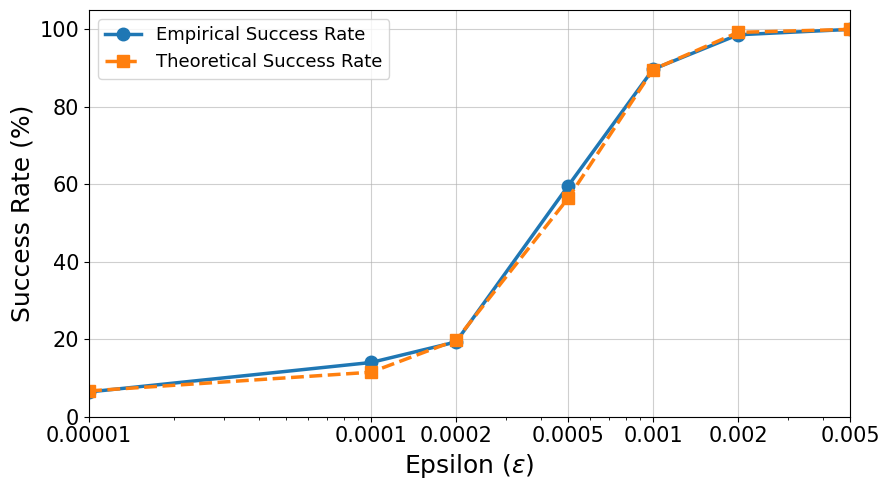

In [49]:
import matplotlib.pyplot as plt
from google.colab import files

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    results_exp_df["Epsilon"],
    results_exp_df["Empirical Success Rate (%)"],
    marker="o",
    markersize=9,
    linewidth=2.5,
    label="Empirical Success Rate"
)

ax.plot(
    results_exp_df["Epsilon"],
    results_exp_df["Theoretical Success Rate (%)"],
    marker="s",
    markersize=9,
    linewidth=2.5,
    linestyle="--",
    label="Theoretical Success Rate"
)

ax.set_xscale("log")
ax.set_xticks([0.00001, 0.0001, 0.0002, 0.0005,
               0.001, 0.002, 0.005])
ax.set_xticklabels(["0.00001", "0.0001", "0.0002", "0.0005",
                    "0.001", "0.002", "0.005"])
ax.set_xlim(0.00001, 0.005)

ax.set_xlabel(r"Epsilon ($\varepsilon$)", fontsize=18)
ax.set_ylabel("Success Rate (%)", fontsize=18)
ax.set_ylim(0, 105)

ax.tick_params(axis="both", which="major", labelsize=15)
ax.legend(fontsize=13)
ax.grid(True, linewidth=0.8, alpha=0.6)

fig.tight_layout()

fig.savefig("exponential_success_rate.pdf")
plt.show()

**Exponential Mechanism - Selection Distribution**

In this experiment, we analyze how the Exponential Mechanism distributes its selections among the 16 education categories for different values of $\varepsilon$.

We consider four representative values of $\varepsilon$: 0.00001, 0.0002, 0.001, and 0.005.

For each value, we run the Exponential Mechanism 1,000 times and calculate the empirical selection frequency of each category. We then compare these frequencies with the corresponding theoretical selection probabilities.

The results are displayed using four bar charts, where empirical and theoretical values are shown side by side. The optimal category, HS-grad, is highlighted in red to make its selection frequency easier to identify.

As $\varepsilon$ increases, the probability of selecting categories with higher utility becomes greater, concentrating the distribution around the optimal category. This allows us to observe how the selection behavior of the Exponential Mechanism changes with different privacy levels.

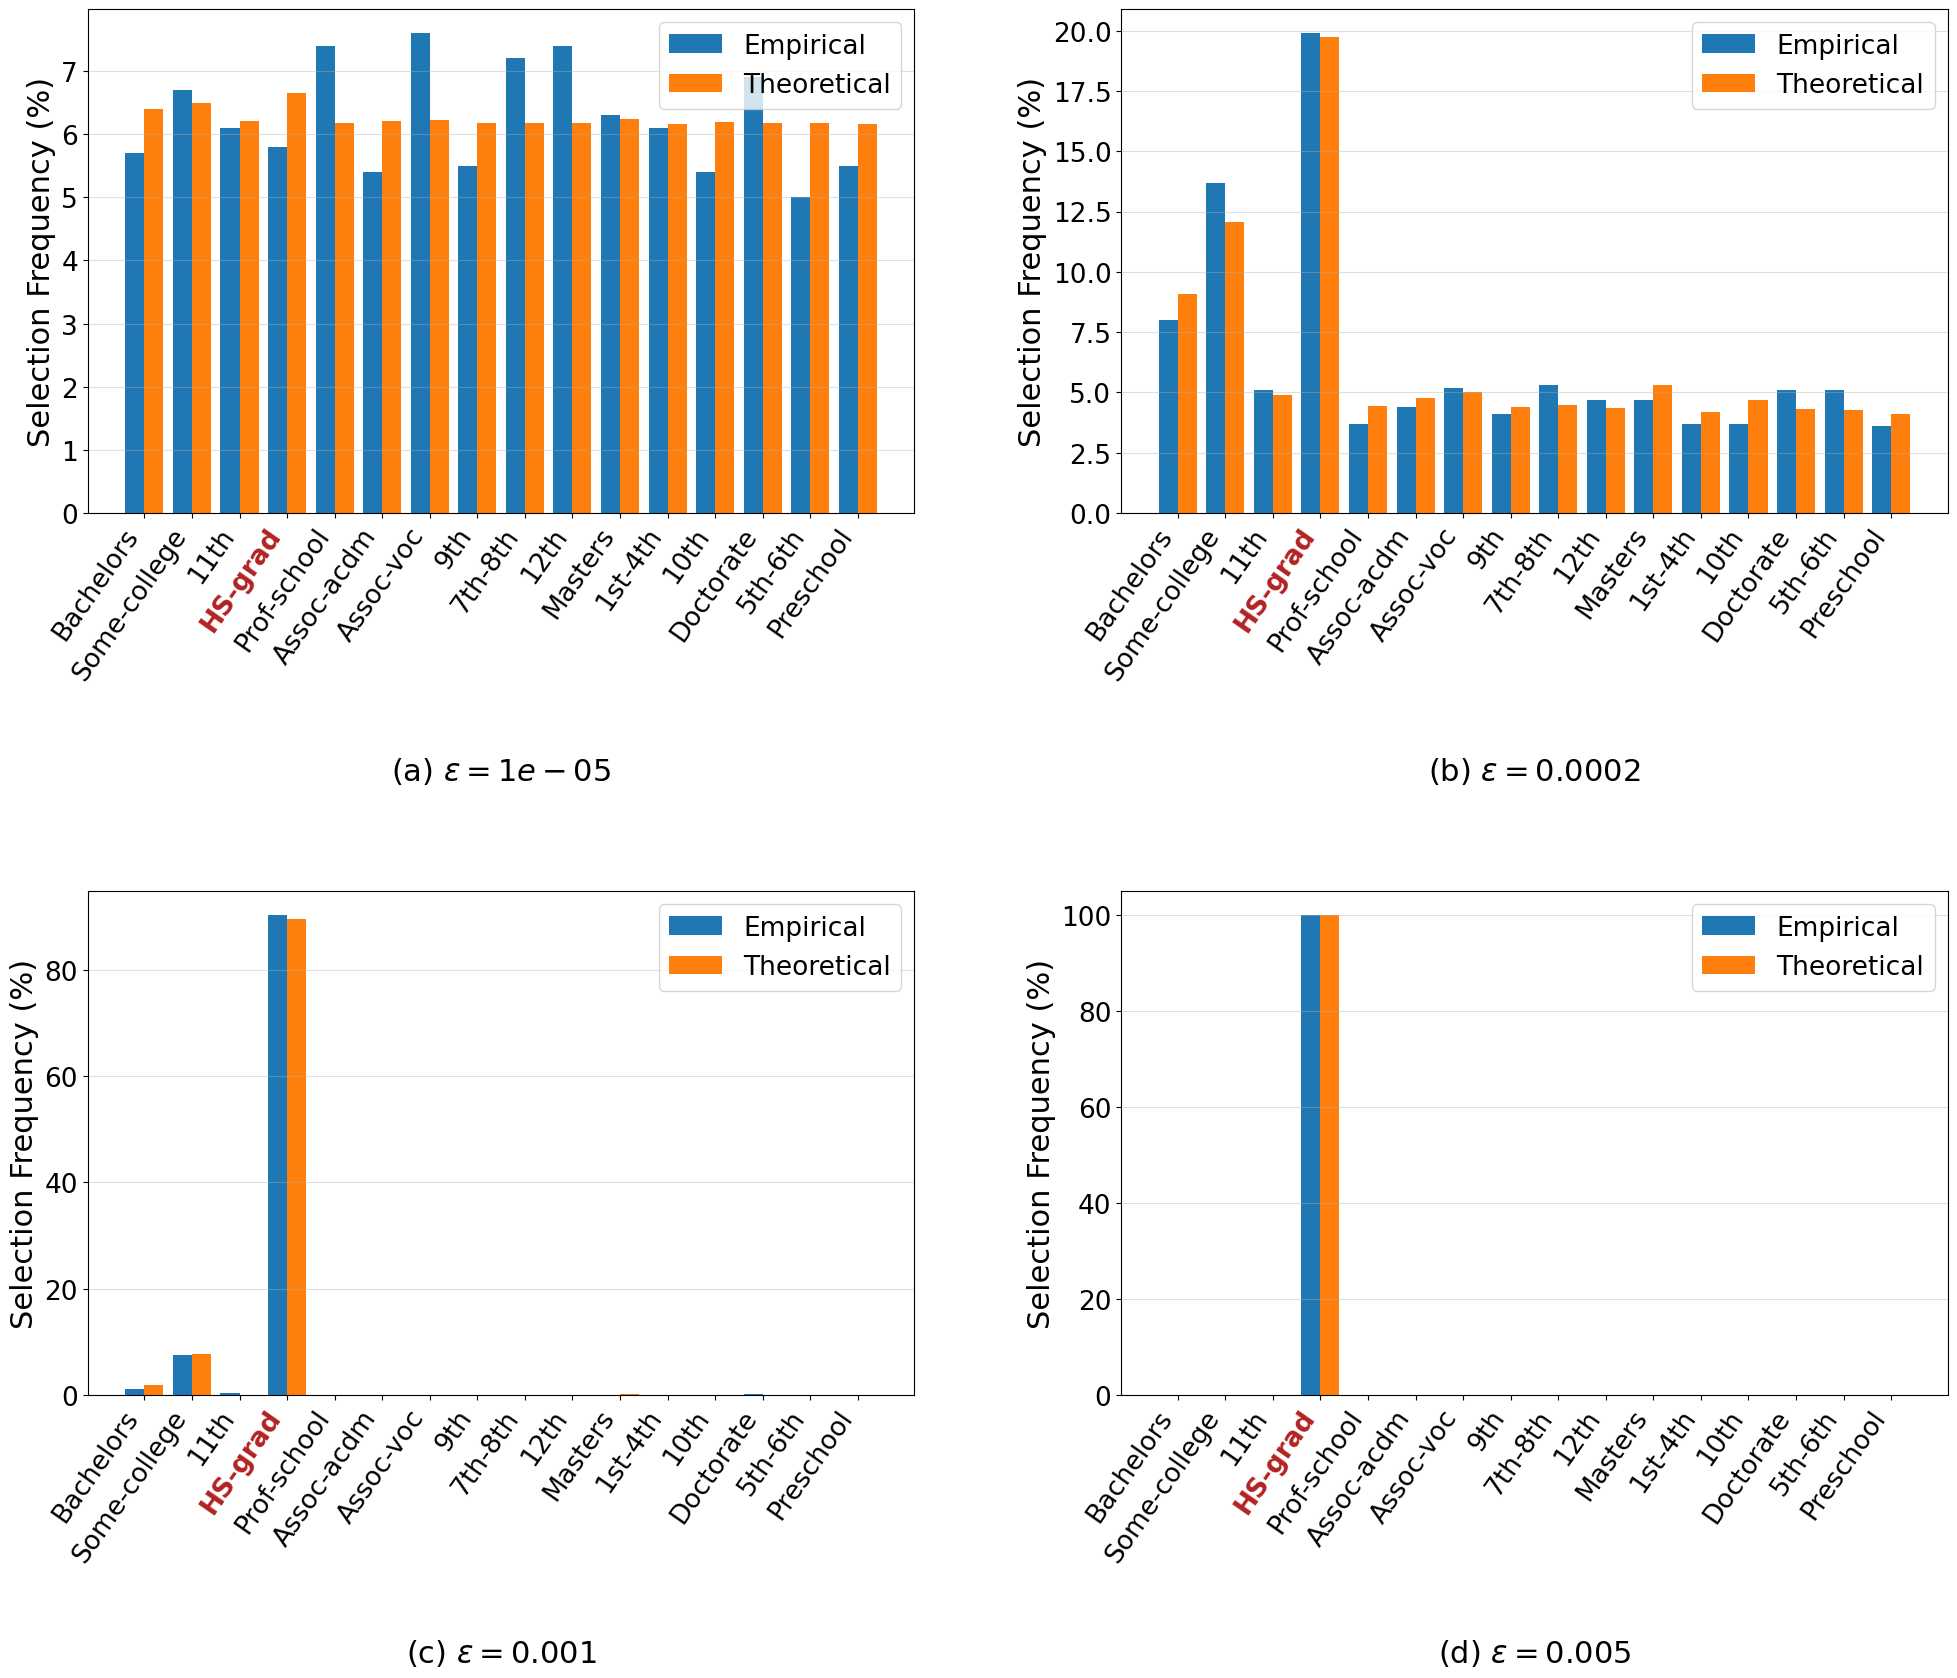

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

epsilons_plot = [0.00001, 0.0002, 0.001, 0.005]
letters = ["a", "b", "c", "d"]

fig, axes = plt.subplots(2, 2, figsize=(24, 18))
axes = axes.flatten()

for epsilon, letter, ax in zip(epsilons_plot, letters, axes):

    selected_categories = [
        exponential_mechanism(categories, utilities, epsilon)
        for _ in range(1000)
    ]

    empirical_probs = (
        pd.Series(selected_categories)
        .value_counts(normalize=True)
        .reindex(categories, fill_value=0)
        .to_numpy()
    )

    scores = epsilon * utilities / 2
    weights = np.exp(scores - np.max(scores))
    theoretical_probs = weights / np.sum(weights)

    x = np.arange(len(categories))

    ax.bar(
        x - 0.2,
        empirical_probs * 100,
        width=0.4,
        label="Empirical"
    )

    ax.bar(
        x + 0.2,
        theoretical_probs * 100,
        width=0.4,
        label="Theoretical"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        categories,
        rotation=55,
        ha="right",
        fontsize=19
    )

    for label in ax.get_xticklabels():
        if label.get_text() == "HS-grad":
            label.set_color("firebrick")
            label.set_fontweight("bold")

    ax.set_ylabel("Selection Frequency (%)", fontsize=22)
    ax.tick_params(axis="y", labelsize=19)

    ax.text(
        0.5, -0.48,
        rf"({letter}) $\varepsilon = {epsilon:g}$",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=22
    )

    ax.legend(fontsize=19)
    ax.grid(axis="y", linewidth=0.8, alpha=0.4)

fig.subplots_adjust(
    hspace=0.75,
    wspace=0.25,
    bottom=0.18,
    top=0.95
)

fig.savefig(
    "selection_distribution.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


**Exponential Mechanism - Average Utility Loss**

In this experiment, we evaluate the Average Utility Loss of the Exponential Mechanism for different values of $\varepsilon$.

The utility function is defined as the number of individuals belonging to each education category. The optimal category is the one with the highest utility, which is HS-grad in our dataset, with 15,784 individuals.

For each value of $\varepsilon$, we calculate the theoretical selection probabilities and run the Exponential Mechanism 1,000 times.

The utility loss is defined as the difference between the utility of the optimal category and the utility of the selected category. We then calculate the empirical Average Utility Loss from the simulations and compare it with its theoretical value, obtained using the selection probabilities.

As $\varepsilon$ increases, the Average Utility Loss is expected to decrease because the mechanism assigns higher probabilities to categories with higher utility values. This allows us to evaluate how the accuracy of the mechanism improves as the privacy guarantee becomes weaker.

In [51]:

import numpy as np
import pandas as pd

categories = [
    "Bachelors", "Some-college", "11th", "HS-grad",
    "Prof-school", "Assoc-acdm", "Assoc-voc", "9th",
    "7th-8th", "12th", "Masters", "1st-4th",
    "10th", "Doctorate", "5th-6th", "Preschool"
]

utility_scores = (
    df["education"]
    .value_counts()
    .reindex(categories, fill_value=0)
)

utilities = utility_scores.to_numpy()

optimal_category = utility_scores.idxmax()
optimal_utility = utility_scores.max()

print("Optimal category:", optimal_category)
print("Optimal utility:", optimal_utility)


epsilons_exp = [
    0.00001, 0.0001, 0.0002, 0.0005,
    0.001, 0.002, 0.005
]

n_runs = 1000
rng_utility = np.random.default_rng(123)

results_loss = []

for epsilon in epsilons_exp:

    scores = epsilon * utilities / 2
    weights = np.exp(scores - np.max(scores))
    probabilities = weights / np.sum(weights)

    selected_indices = rng_utility.choice(
        len(categories),
        size=n_runs,
        p=probabilities
    )

    selected_utilities = utilities[selected_indices]
    losses = optimal_utility - selected_utilities

    empirical_loss = np.mean(losses)

    theoretical_loss = np.sum(
        probabilities * (optimal_utility - utilities)
    )

    results_loss.append({
        "Epsilon": epsilon,
        "Empirical Average Utility Loss": empirical_loss,
        "Theoretical Average Utility Loss": theoretical_loss
    })

results_loss_df = pd.DataFrame(results_loss)

display(
    results_loss_df.style.format({
        "Epsilon": "{:.5f}",
        "Empirical Average Utility Loss": "{:.3f}",
        "Theoretical Average Utility Loss": "{:.3f}"
    })
)


Optimal category: HS-grad
Optimal utility: 15784


,Epsilon,Empirical Average Utility Loss,Theoretical Average Utility Loss
0,0.00001,12777.608,12634.024
1,0.00010,11164.469,11565.382
2,0.00020,9974.908,9953.542
3,0.00050,3823.426,4196.993
4,0.00100,639.959,638.114
5,0.00200,71.537,39.420
6,0.00500,0.000,0.023


**Exponential Mechanism - Average Utility Loss Visualization**

In this section, we plot the empirical and theoretical Average Utility Loss for different values of $\varepsilon$.

The empirical values are obtained from the 1,000 simulations, while the theoretical values are calculated using the selection probabilities of the Exponential Mechanism.

We use a logarithmic scale for the x-axis to better represent the different values of $\varepsilon$.

As $\varepsilon$ increases, the Average Utility Loss is expected to decrease because the mechanism assigns higher probabilities to categories with higher utility values.

The empirical and theoretical curves are expected to be close, with small differences due to the randomness of the simulations.

This visualization illustrates how the utility loss decreases as the privacy guarantee becomes weaker.

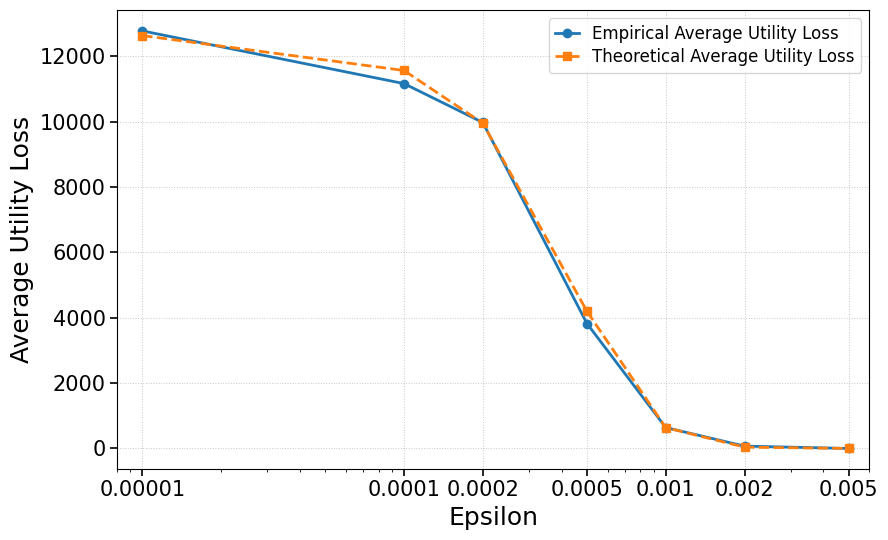

In [52]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.plot(
    results_loss_df["Epsilon"],
    results_loss_df["Empirical Average Utility Loss"],
    marker="o",
    markersize=6,
    linewidth=2,
    label="Empirical Average Utility Loss"
)

ax.plot(
    results_loss_df["Epsilon"],
    results_loss_df["Theoretical Average Utility Loss"],
    marker="s",
    markersize=6,
    linestyle="--",
    linewidth=2,
    label="Theoretical Average Utility Loss"
)

ax.set_xscale("log")
ax.set_xlim(0.000008, 0.006)

ax.set_xlabel("Epsilon", fontsize=18, labelpad=4)
ax.set_ylabel("Average Utility Loss", fontsize=18, labelpad=4)

epsilons = [0.00001, 0.0001, 0.0002, 0.0005,
            0.001, 0.002, 0.005]

ax.set_xticks(epsilons)
ax.set_xticklabels([
    "0.00001",
    "0.0001",
    "0.0002",
    "0.0005",
    "0.001",
    "0.002",
    "0.005"
])

ax.tick_params(
    axis="both",
    labelsize=15,
    pad=3,
    width=1.2,
    length=5
)

ax.legend(
    fontsize=12,
    loc="best",
    handlelength=1.4,
    borderpad=0.4,
    labelspacing=0.3
)

ax.grid(True, linestyle=":", linewidth=0.7, alpha=0.7)

fig.tight_layout()

fig.savefig("exponential_utility_loss.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

**Exponential Mechanism – Experimental Evaluation: Theoretical Utility Loss Bound**

In this experiment, we evaluate the theoretical utility loss bound of the Exponential Mechanism using the Adult Census dataset.

We consider 16 education categories, where HS-grad is the only category with maximum utility. The utility of each category corresponds to the number of individuals belonging to it, and its sensitivity is $\Delta u=1$. We set $t=\ln 10$, resulting in a theoretical probability bound of 10%.

For each value of $\varepsilon$, we calculate the corresponding utility loss threshold. We then run the Exponential Mechanism 1,000 times and compute the empirical average utility loss. We also calculate the theoretical average utility loss directly from the output probabilities and the percentage of simulations in which the utility loss is greater than or equal to the theoretical threshold.

Finally, we compare the thresholds with the maximum possible utility loss in the dataset, which is 15,701, to assess whether the theoretical bound provides a meaningful guarantee for each value of $\varepsilon$.

In [53]:

import numpy as np
import pandas as pd

categories = sorted(df["education"].dropna().unique())

counts = (
    df["education"]
    .value_counts()
    .reindex(categories, fill_value=0)
    .to_numpy()
)

epsilons = [
    0.00001, 0.0001, 0.0002, 0.0005,
    0.001, 0.002, 0.005
]

N = 1000
t = np.log(10)
delta_u = 1

R = len(categories)
R_opt = np.sum(counts == counts.max())

u_star = counts.max()
max_loss = u_star - counts.min()

def em_probs(counts, eps, delta_u=1):
    scores = eps * counts / (2 * delta_u)
    scores = scores - np.max(scores)
    weights = np.exp(scores)
    return weights / weights.sum()

rng = np.random.default_rng(123)
rows = []

for eps in epsilons:
    probabilities = em_probs(counts, eps, delta_u)

    selected = rng.choice(
        len(categories),
        size=N,
        p=probabilities
    )

    losses = u_star - counts[selected]

    empirical_loss = losses.mean()
    theoretical_loss = np.sum(
        probabilities * (u_star - counts)
    )

    bound = (2 * delta_u / eps) * (
        np.log(R / R_opt) + t
    )

    frac_above = np.mean(losses >= bound) * 100

    rows.append({
        "Epsilon": eps,
        "Utility Loss Threshold": bound,
        "Empirical Average Loss": empirical_loss,
        "Theoretical Average Loss": theoretical_loss,
        "Simulations Above Threshold (%)": frac_above
    })

results_df = pd.DataFrame(rows)

display(results_df.style.format({
    "Epsilon": "{:.5f}",
    "Utility Loss Threshold": "{:,.1f}",
    "Empirical Average Loss": "{:,.0f}",
    "Theoretical Average Loss": "{:,.0f}",
    "Simulations Above Threshold (%)": "{:.1f}"
}))

print(f"Number of categories: {R}")
print(f"Number of optimal categories: {R_opt}")
print(f"Maximum possible utility loss: {max_loss:,}")
print(f"Theoretical probability bound: {np.exp(-t):.1%}")


,Epsilon,Utility Loss Threshold,Empirical Average Loss,Theoretical Average Loss,Simulations Above Threshold (%)
0,0.00001,"1,015,034.8","12,497","12,634",0.0
1,0.00010,"101,503.5","11,702","11,565",0.0
2,0.00020,"50,751.7","10,117","9,954",0.0
3,0.00050,"20,300.7","4,258","4,197",0.0
4,0.00100,"10,150.3",615,638,1.3
5,0.00200,"5,075.2",37,39,0.1
6,0.00500,"2,030.1",0,0,0.0


Number of categories: 16
Number of optimal categories: 1
Maximum possible utility loss: 15,701
Theoretical probability bound: 10.0%
